In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [7]:
# 1. Load Data
# # Assuming your results are in this file
# df = pd.read_csv("data/benchmark_results_v7.csv")
df = pd.read_csv("../data/benchmark_results_article.csv")
df = df[df['Time_Sec'] < 1000]  # Filter out runs that took more than 1 hour

# -------------------------------------------------------
# CONFIGURATION
# -------------------------------------------------------
# Since we now support multiple estimators (RF, XGB, etc.), 
# let's filter for 'extra_trees' for the main visualization 
# to avoid overplotting. Change this to 'xgb' or 'lgbm' to see others.
TARGET_ESTIMATOR = 'extra_trees'
# TARGET_ESTIMATOR = 'rf'
df = df[df['Estimator'] == TARGET_ESTIMATOR].copy()

print(f"Visualizing results for estimator: {TARGET_ESTIMATOR}")
df.head()

Visualizing results for estimator: extra_trees


,Dataset,Task,n_samples,n_features_orig,Estimator,Method,Alpha,Run_ID,Time_Sec,Iterations,N_Confirmed,N_Tentative,Ratio_Selected,Score_Confirmed_Mean,Score_Confirmed_Std,Score_All_Mean,Score_All_Std
0,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,0,2.851742,-1,24,0,0.048,0.850364,0.014666,0.850364,0.014666
1,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,1,2.330664,-1,23,0,0.046,0.863749,0.022620,0.863749,0.022620
2,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,2,2.328686,-1,27,0,0.054,0.857301,0.014765,0.857301,0.014765
3,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,3,2.321240,-1,27,0,0.054,0.852286,0.008381,0.852286,0.008381
4,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,4,2.298126,-1,28,0,0.056,0.853394,0.013401,0.853394,0.013401


In [8]:
# We need to "explode" the dataframe because Vanilla has TWO scores per run 
# (Confirmed Only vs. All including Tentative), while Greedy only has one.
analysis_rows = []

for idx, row in df.iterrows():
    # 1. Handle Greedy Variants (Parallel or Serial)
    if 'Greedy' in row['Method']:
        analysis_rows.append({
            'Dataset': row['Dataset'],
            'Task': row['Task'],
            'Alpha': str(row['Alpha']),
            'Method_Variant': row['Method'], # Keeps "Greedy" or "GreedyParallel"
            'Score': row['Score_Confirmed_Mean'],
            'Time_Sec': row['Time_Sec'],
            'Selected_Feats': row['N_Confirmed']
        })
    
    # 2. Handle Vanilla Entries (Split into two variants)
    elif row['Method'] == 'Vanilla':
        # Variant A: Strict (Confirmed Only)
        analysis_rows.append({
            'Dataset': row['Dataset'],
            'Task': row['Task'],
            'Alpha': str(row['Alpha']),
            'Method_Variant': 'Vanilla (Strict)',
            'Score': row['Score_Confirmed_Mean'],
            'Time_Sec': row['Time_Sec'],
            'Selected_Feats': row['N_Confirmed']
        })
        
        # Variant B: Soft (Confirmed + Tentative)
        analysis_rows.append({
            'Dataset': row['Dataset'],
            'Task': row['Task'],
            'Alpha': str(row['Alpha']),
            'Method_Variant': 'Vanilla (Soft/All)',
            'Score': row['Score_All_Mean'],
            'Time_Sec': row['Time_Sec'],
            'Selected_Feats': row['N_Confirmed'] + row['N_Tentative']
        })

df_viz = pd.DataFrame(analysis_rows)
print("Data reshaped. Head:")
df_viz.head()

Data reshaped. Head:


,Dataset,Task,Alpha,Method_Variant,Score,Time_Sec,Selected_Feats
0,Madelon,class,0.1,GreedyParallel,0.850364,2.851742,24
1,Madelon,class,0.1,GreedyParallel,0.863749,2.330664,23
2,Madelon,class,0.1,GreedyParallel,0.857301,2.328686,27
3,Madelon,class,0.1,GreedyParallel,0.852286,2.321240,27
4,Madelon,class,0.1,GreedyParallel,0.853394,2.298126,28


In [9]:
from scipy import stats
import pandas as pd
import numpy as np

def run_statistical_tests(df_viz, significance_level=0.1):
    datasets = df_viz['Dataset'].unique()
    alphas = df_viz['Alpha'].unique()
    
    results = []
    
    for dataset in datasets:
        for alpha in alphas:
            # 1. Filter Data
            subset = df_viz[(df_viz['Dataset'] == dataset) & (df_viz['Alpha'] == alpha)]
            
            # 2. Identify Groups
            # Prefer GreedyParallel, fallback to Greedy
            greedy_scores = subset[subset['Method_Variant'] == 'GreedyParallel']['Score']
            if len(greedy_scores) == 0:
                greedy_scores = subset[subset['Method_Variant'] == 'Greedy']['Score']
                
            vanilla_strict_scores = subset[subset['Method_Variant'] == 'Vanilla (Strict)']['Score']
            
            # We need at least 2 samples per group for a t-test
            if len(greedy_scores) < 2 or len(vanilla_strict_scores) < 2:
                continue
            
            # 3. Perform Tests (Greedy vs Vanilla Strict)
            
            # Test A: Is there ANY difference? (Two-sided)
            # H0: means are equal. H1: means are different.
            t_stat, p_diff = stats.ttest_ind(greedy_scores, vanilla_strict_scores, equal_var=False, alternative='two-sided')
            
            # Test B: Is Greedy BETTER? (One-sided Greater)
            # H0: Greedy <= Vanilla. H1: Greedy > Vanilla
            _, p_greedy_wins = stats.ttest_ind(greedy_scores, vanilla_strict_scores, equal_var=False, alternative='greater')
            
            # Test C: Is Vanilla BETTER? (One-sided Less) (equivalent to testing Vanilla > Greedy)
            # H0: Greedy >= Vanilla. H1: Greedy < Vanilla
            _, p_vanilla_wins = stats.ttest_ind(greedy_scores, vanilla_strict_scores, equal_var=False, alternative='less')

            # 4. Determine "Winner" (at significance level = significance_level)
            winner = "Tie"
            if p_greedy_wins < significance_level:
                winner = "Greedy"
            elif p_vanilla_wins < significance_level:
                winner = "Vanilla"
            
            # Calculate Speedup for context
            greedy_time = subset[subset['Method_Variant'].str.contains('Greedy')]['Time_Sec'].mean()
            vanilla_time = subset[subset['Method_Variant'].str.contains('Vanilla')]['Time_Sec'].mean()
            speedup = vanilla_time / greedy_time if greedy_time > 0 else 0

            results.append({
                'Dataset': dataset,
                'Alpha': alpha,
                'Speedup': speedup,
                'Greedy_Mean': greedy_scores.mean(),
                'Vanilla_Mean': vanilla_strict_scores.mean(),
                'Diff (G-V)': greedy_scores.mean() - vanilla_strict_scores.mean(),
                'Winner_Stat': winner,
                'P_Any_Diff': p_diff,
                'P_Greedy_Better': p_greedy_wins,
                'P_Vanilla_Better': p_vanilla_wins
            })
            
    return pd.DataFrame(results)

# ---------------------------------------------------------
# EXECUTION AND PRINTING
# ---------------------------------------------------------
if not df_viz[df_viz['Method_Variant'].str.contains('Vanilla')].empty:
    stats_df = run_statistical_tests(df_viz)
    
    # Filter columns for a clean display
    display_cols = [
        'Dataset', 'Alpha', 'Speedup', 
        'Greedy_Mean', 'Vanilla_Mean', 
        'Winner_Stat', 
        'P_Greedy_Better', 'P_Vanilla_Better'
    ]
    
    print("\nDirectional Statistical Comparison (Significance level = 0.05)")
    print("-" * 100)
    # Rounding for readability
    print(stats_df[display_cols].round(4).to_string(index=False))
    
    print("-" * 100)
    print("Note: 'Winner_Stat' refers only to Score (F1/R2).") 
    print("If Winner is 'Tie' but Speedup >> 1, Greedy is functionally superior.")
else:
    print("Skipping stats: Missing Vanilla data.")


Directional Statistical Comparison (Significance level = 0.05)
----------------------------------------------------------------------------------------------------
   Dataset Alpha  Speedup  Greedy_Mean  Vanilla_Mean Winner_Stat  P_Greedy_Better  P_Vanilla_Better
   Madelon   0.1  14.6238       0.8556        0.8620     Vanilla           0.9910            0.0090
   Madelon 0.001  10.8509       0.8561        0.8662     Vanilla           0.9996            0.0004
   Madelon 1e-05   9.5124       0.8553        0.8659     Vanilla           1.0000            0.0000
    Arcene   0.1  16.3917       0.8680        0.8780     Vanilla           0.9321            0.0679
    Arcene 0.001  14.5620       0.8745        0.8785         Tie           0.7359            0.2641
    Arcene 1e-05  10.8588       0.8746        0.8776         Tie           0.6437            0.3563
   Gisette   0.1  22.9995       0.9824        0.9820         Tie           0.2175            0.7825
   Gisette 0.001  16.0961       0.9

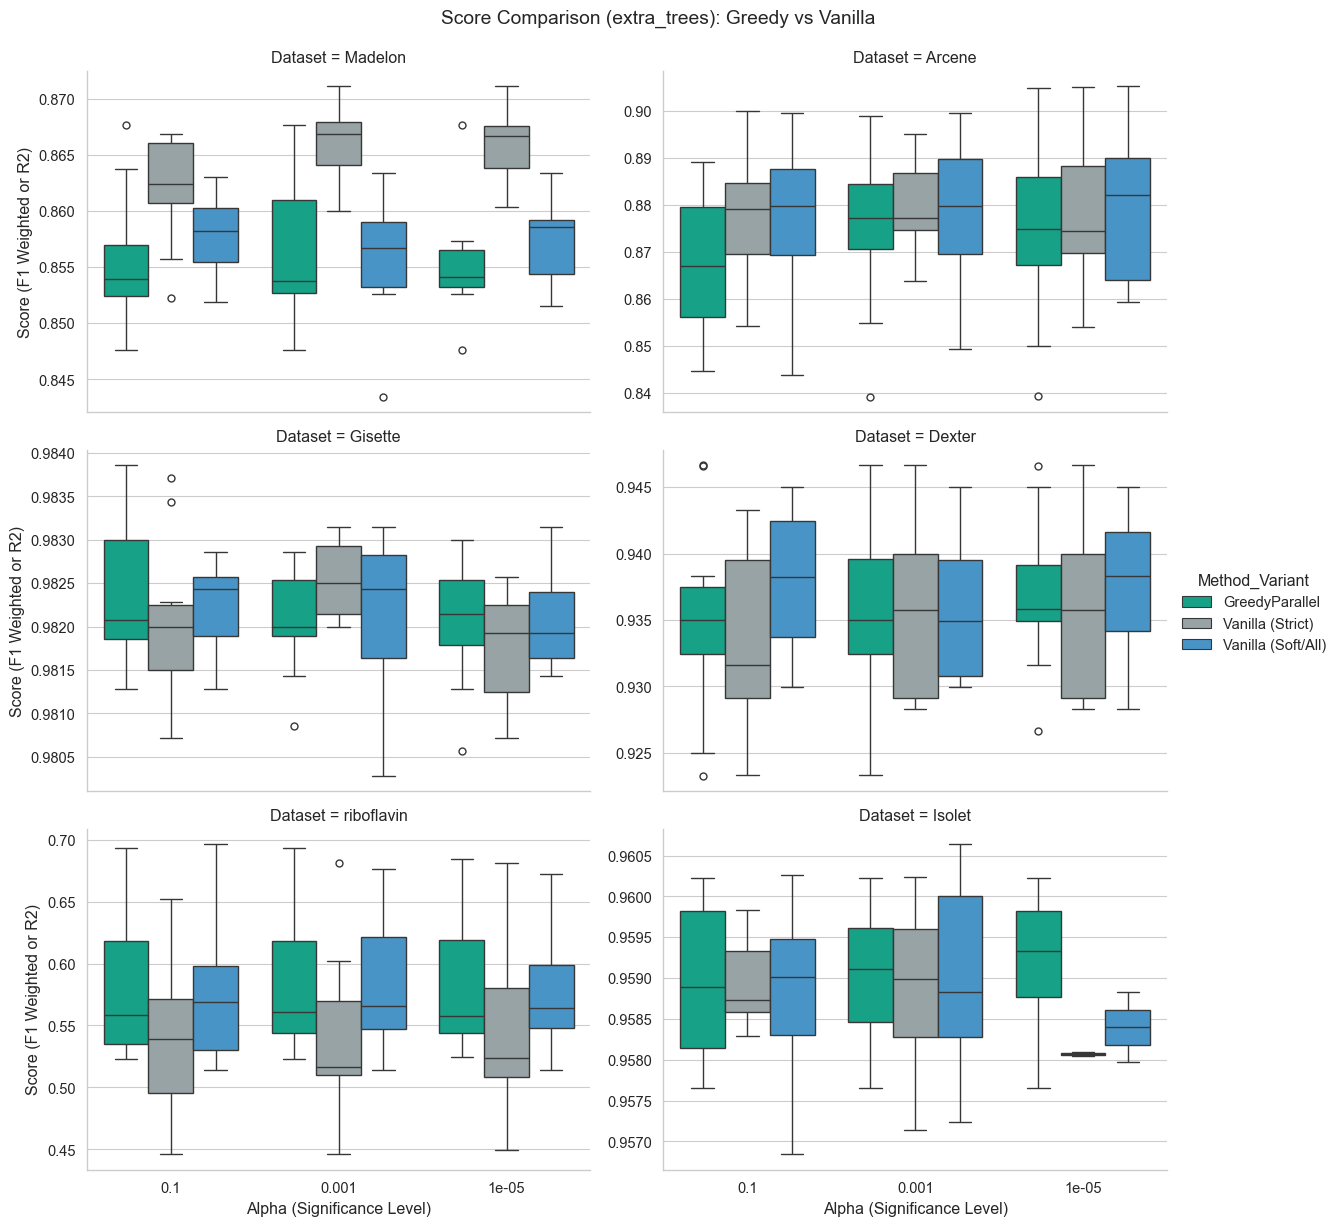

In [10]:
# Set Style
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# Define Palette manually to ensure consistency
my_pal = {
    "Greedy": "#2ecc71", 
    "GreedyParallel": "#00b894", 
    "Vanilla (Strict)": "#95a5a6", 
    "Vanilla (Soft/All)": "#3498db"
}

g = sns.catplot(
    data=df_viz,
    x="Alpha", 
    y="Score", 
    hue="Method_Variant",
    col="Dataset", 
    kind="box",
    col_wrap=2,
    height=4, 
    aspect=1.5,
    palette=my_pal,
    sharey=False # Crucial: R2 (Reg) and F1 (Class) have different ranges
)

g.fig.suptitle(f"Score Comparison ({TARGET_ESTIMATOR}): Greedy vs Vanilla", y=1.02)
g.set_ylabels("Score (F1 Weighted or R2)")
g.set_xlabels("Alpha (Significance Level)")

plt.show()

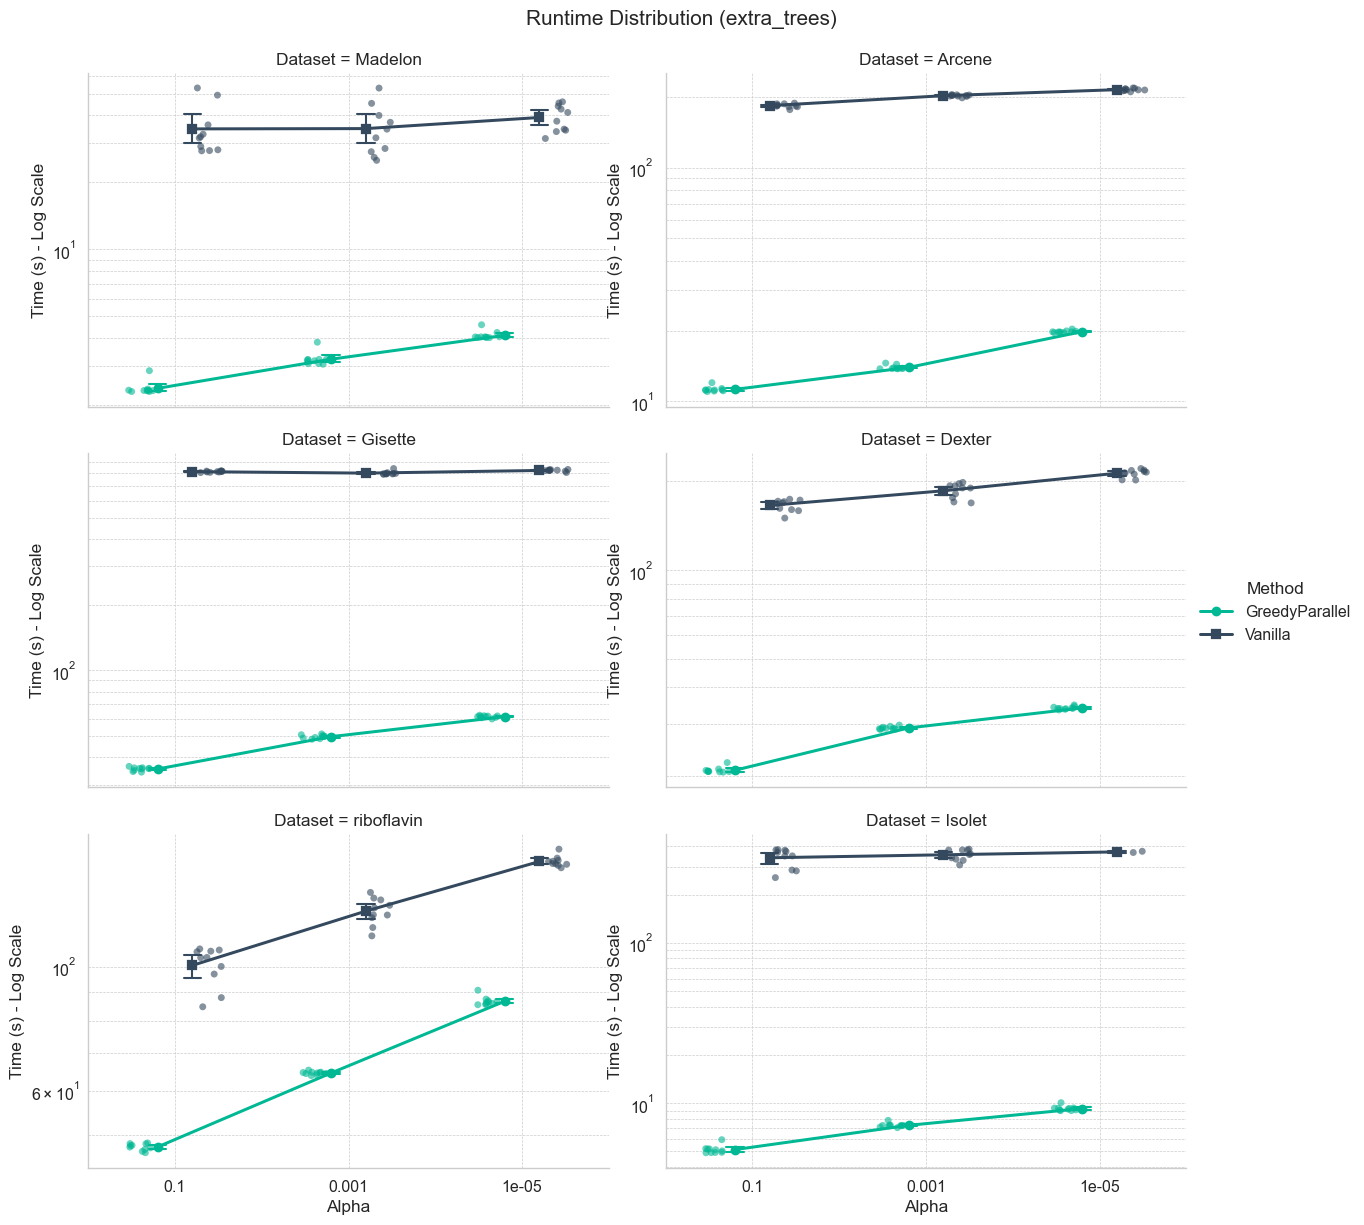

In [11]:
# Load Data (using the original df to get raw 'Method' column)
df_plot = df.copy()
df_plot['Alpha'] = df_plot['Alpha'].astype(str)

# Setup Canvas
sns.set_theme(style="whitegrid", context="paper", font_scale=1.3)
g = sns.FacetGrid(df_plot, col="Dataset", col_wrap=2, height=4, aspect=1.5, sharey=False)

# 1. Draw the "Trend" (Mean + Error Bars)
g.map_dataframe(
    sns.pointplot, x="Alpha", y="Time_Sec", hue="Method",
    palette={"Greedy": "#2ecc71", "GreedyParallel": "#00b894", "Vanilla": "#34495e"},
    dodge=0.2, markers=["o", "s", "^"], capsize=0.1, err_kws={'linewidth': 1.5}
)

# 2. Draw the "Raw Data" (Jittered Points)
g.map_dataframe(
    sns.stripplot, x="Alpha", y="Time_Sec", hue="Method",
    palette={"Greedy": "#2ecc71", "GreedyParallel": "#00b894", "Vanilla": "#34495e"},
    dodge=0.1, alpha=0.6, jitter=0.15, size=5, legend=False
)

# Log Scale is crucial
for ax in g.axes.flat:
    ax.set_yscale("log")
    ax.set_ylabel("Time (s) - Log Scale")
    ax.grid(True, which="both", ls="--", linewidth=0.5)

g.add_legend(title="Method")
g.fig.suptitle(f"Runtime Distribution ({TARGET_ESTIMATOR})", y=1.02)
plt.show()

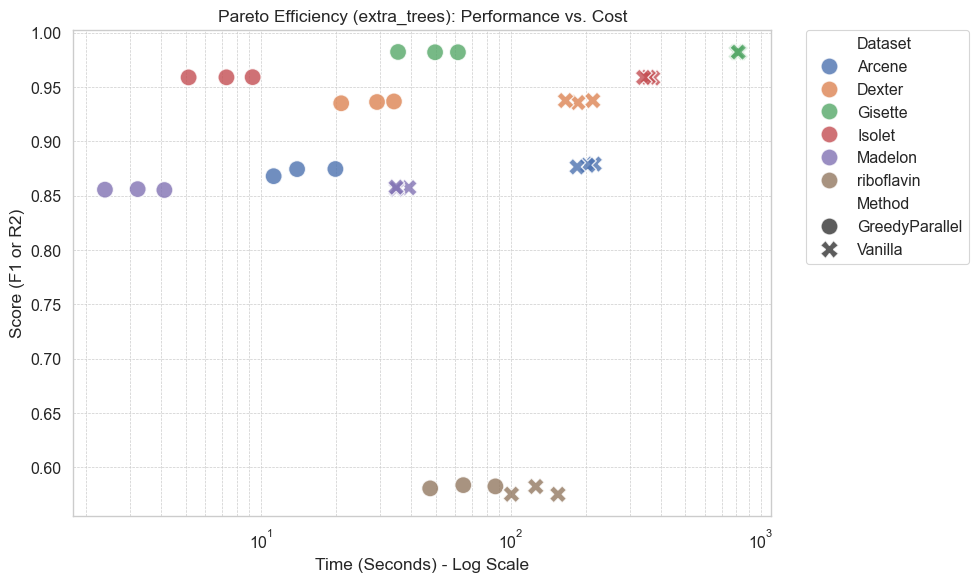

In [12]:
plt.figure(figsize=(10, 6))

# We average across runs
df_avg = df.groupby(['Dataset', 'Method', 'Alpha']).agg({
    'Time_Sec': 'mean',
    'Score_All_Mean': 'mean' # Use 'All' for Vanilla fairness
}).reset_index()

sns.scatterplot(
    data=df_avg, 
    x="Time_Sec", 
    y="Score_All_Mean", 
    hue="Dataset", 
    style="Method", 
    s=150, 
    alpha=0.8,
    palette="deep"
)

plt.xscale("log")
plt.title(f"Pareto Efficiency ({TARGET_ESTIMATOR}): Performance vs. Cost")
plt.xlabel("Time (Seconds) - Log Scale")
plt.ylabel("Score (F1 or R2)")
plt.grid(True, which="both", ls="--", linewidth=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.tight_layout()
plt.show()

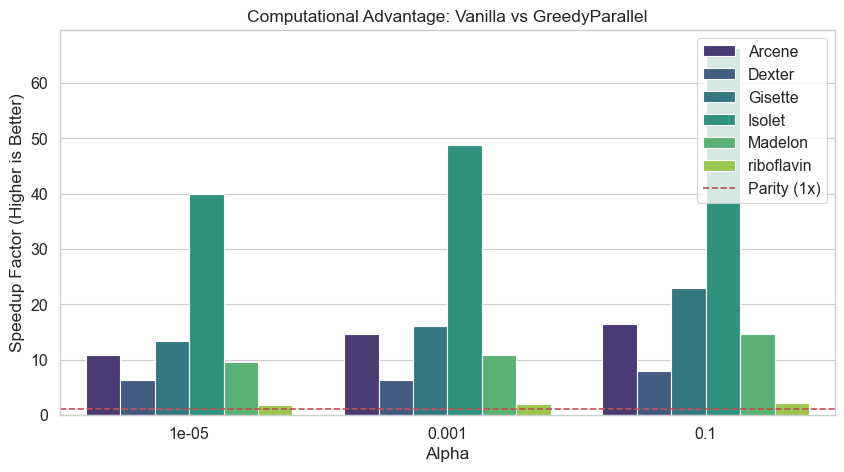

In [13]:
# 1. Pivot data
# We want to compare Vanilla vs GreedyParallel (if available) or Greedy
df_pivot = df.groupby(['Dataset', 'Alpha', 'Method'])['Time_Sec'].mean().unstack()

if 'Vanilla' in df_pivot.columns:
    # Calculate Speedup relative to Vanilla
    if 'GreedyParallel' in df_pivot.columns:
        df_pivot['Speedup_Factor'] = df_pivot['Vanilla'] / df_pivot['GreedyParallel']
        compare_label = "Vanilla vs GreedyParallel"
    else:   
        df_pivot['Speedup_Factor'] = df_pivot['Vanilla'] / df_pivot['Greedy']
        compare_label = "Vanilla vs Greedy"
        
    df_pivot = df_pivot.reset_index()

    # 2. Visualization
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=df_pivot,
        x="Alpha",
        y="Speedup_Factor",
        hue="Dataset",
        palette="viridis"
    )

    plt.title(f"Computational Advantage: {compare_label}")
    plt.ylabel("Speedup Factor (Higher is Better)")
    plt.axhline(1, color='r', linestyle='--', label="Parity (1x)")
    plt.legend()
    plt.show()
else:
    print("Cannot plot Speedup: 'Vanilla' method missing from results.")